# Preprocessing Data Incident — Unit Surabaya

Sumber: `Data_Incident_test.xlsx` (sheet **Data Incident**).

Tahapan:
1. Load data mentah & ekstraksi metadata laporan
2. Deteksi baris header & ambil tabel insiden
3. Standarisasi nama kolom
4. Pembersihan teks & normalisasi nilai kosong/placeholder
5. Parsing tanggal (format Indonesia)
6. Pemecahan kolom `Jam/Lokasi`
7. Pembersihan kolom teks multi-nilai
8. Normalisasi `Tipe Kecelakaan` (kategori + tingkat)
9. Konversi kolom numerik
10. Nomor insiden & feature engineering
11. Kategori, duplikat, validasi
12. Ringkasan & visualisasi singkat
13. Ekspor hasil

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)

FILE_PATH = "Data_Incident_test.xlsx"
SHEET = "Data Incident"

## 1. Load data mentah & metadata laporan

In [2]:
raw = pd.read_excel(FILE_PATH, sheet_name=SHEET, header=None)
print("Shape mentah:", raw.shape)
raw.head(16)

Shape mentah: (104, 22)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
0,Data Incident,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Unit : Surabaya,NaN,Month : ALL,NaN,Year : 0,NaN,Klasifikasi Insiden : ALL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,Status CAPA : ALL,NaN,Status Investigasi : ALL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NUMBER OF EMPLOYEES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Operations,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Contractor,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,WORKING HOURS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Normal working hours,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Ekstraksi metadata dari blok atas (sebelum tabel)
header_row = raw.index[raw[0].astype(str).str.strip().eq("Nomor Insiden")][0]
meta_block = raw.iloc[:header_row]

metadata = {}
for val in meta_block.values.ravel():
    if isinstance(val, str) and ":" in val:
        k, v = val.split(":", 1)
        metadata[k.strip()] = v.strip()
for _, row in meta_block.iterrows():
    label = row[0]
    if isinstance(label, str) and pd.notna(row[1]) and ":" not in label:
        metadata[label.strip()] = row[1]

print("Baris header tabel:", header_row)
pd.Series(metadata, name="value").to_frame()

Baris header tabel: 12


,value
Unit,Surabaya
Month,ALL
Year,0
Klasifikasi Insiden,ALL
Status CAPA,ALL
Status Investigasi,ALL
Operations,0
Contractor,0
Normal working hours,0
Overtime,0


## 2. Ambil tabel insiden

In [4]:
df = pd.read_excel(FILE_PATH, sheet_name=SHEET, header=header_row)
df = df.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)
print("Shape tabel:", df.shape)
df.head()

Shape tabel: (90, 22)


,Nomor Insiden,Hari/Tanggal,Jam/Lokasi,Tanggal Pelaporan,Department,Nama Korban,NIK,Jabatan,Supervisor Langsung,Dept. Head,Deskripsi Kejadian,Tindakan Tidak Aman,Kondisi Tidak Aman,Faktor Pribadi,Faktor Pekerjaan,Tipe Kecelakaan,Estimasi Biaya,Lost Worked Days,Tindakan Perbaikan,Status Investigasi,Status CAPA,Source
0,INC/SBY/2026/012,"Rabu , 14 Okt 2026",10.01 - 11.00 / pertigaan genset dan laboratorium,"Rabu , 14 Okt 2026",Contractor / Outsourcing,Abdullah,TGJ-092,Sipil,Rudi Yulianto,Didik Wijanarko,Pekerja kontraktor PT. Teknindo Global Jaya saat langsir...,NaN,NaN,NaN,NaN,Medical Treatment Injury (MTI),NaN,0.0,NaN,Open,NaN,Web
1,INC/SBY/2026/011,"Kamis , 01 Okt 2026",07.01 - 08.00 / Jalan Teluk Bayur,"Kamis , 01 Okt 2026",Operations,Thomas Theo Filus,22001501,Bulking Officer,Indra Hadianto,Indahwati,Pada Saat keluar dari Jalan Teluk Amurang menuju jalan T...,NaN,Terdapat kendaraan dari arah lain melaju dengan kencang ...,NaN,NaN,Medical Treatment Injury (MTI),NaN,0.0,"Training keselamatan berkendara ,",Closed,Open,Web
2,INC/SBY/2026/010,"Sabtu , 26 Sep 2026",14.01 - 15.00 / Saluran Bak DCT Refinery 3-4,"Minggu , 27 Sep 2026",Contractor / Outsourcing,Ahmad Syafiq Madani,PPP,Helper,Rudi Yulianto,Didik Wijanarko,pekerja Kontraktor PT.Pilar Putra Perkasa melakukan peke...,Mengabaikan potensi bahaya tekanan dan suhu tinggi dari ...,Jalur steam hanya diikat/dihubungkan menggunakan selang ...,pengawas tidak memahami bahaya kegagalan material akibat...,ob Safety Analysis (JSA) dibuat tanpa mengidentifikasi b...,Medical Treatment Injury (MTI),NaN,0.0,"Perubahan jalur steam trap ,Melakukan koordinasi dan sur...",Closed,Closed,Web
3,INC/SBY/2026/009,"Rabu , 16 Sep 2026",06.01 - 07.00 / Jalan Raya Margorejo,"Rabu , 16 Sep 2026",Utility,Sayful Anwar Alamsyah,05010973,Operator,Sugiantoro,Didik Wijanarko,Ketika berangkat kerja menuju pabrik sekitar pukul 06.30...,"terdapat kendaraan motor melaju menerobos lampu merah ,",NaN,NaN,NaN,Medical Treatment Injury (MTI),NaN,0.0,"Sosialisasi keselamatan berkendara ,",Closed,Open,Web
4,INC/SBY/2026/008,"Jumat , 04 Sep 2026",16.01 - 17.00 / Warehouse Finish Goods Marsho,"Sabtu , 05 Sep 2026",Warehouse,-,-,-,Beny Kristian,Indahwati,Sekitar pukul 16:30 operator forklift GBJ Marsho sedang ...,Menata atau menumpuk barang di rak bertingkat tinggi tan...,"Lantai tempat rak berdiri mengalami deformasi ,Konstruks...",Belum adanya training mengenai metode pengisian produk p...,Belum adanya periodic inspection terkait kekuatan dan ke...,Property Damage LOW,NaN,0.0,Dilakukan assessment secara menyeluruh dengan team Racki...,Closed,Open,Web


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Nomor Insiden        62 non-null     str    
 1   Hari/Tanggal         90 non-null     str    
 2   Jam/Lokasi           90 non-null     str    
 3   Tanggal Pelaporan    90 non-null     str    
 4   Department           90 non-null     str    
 5   Nama Korban          89 non-null     str    
 6   NIK                  90 non-null     str    
 7   Jabatan              90 non-null     str    
 8   Supervisor Langsung  62 non-null     str    
 9   Dept. Head           62 non-null     str    
 10  Deskripsi Kejadian   62 non-null     str    
 11  Tindakan Tidak Aman  41 non-null     str    
 12  Kondisi Tidak Aman   37 non-null     str    
 13  Faktor Pribadi       40 non-null     str    
 14  Faktor Pekerjaan     27 non-null     str    
 15  Tipe Kecelakaan      90 non-null     str    
 16  Est

## 3. Standarisasi nama kolom (snake_case)

In [6]:
col_map = {
    "Nomor Insiden": "nomor_insiden",
    "Hari/Tanggal": "hari_tanggal_kejadian",
    "Jam/Lokasi": "jam_lokasi",
    "Tanggal Pelaporan": "tanggal_pelaporan_raw",
    "Department": "department",
    "Nama Korban": "nama_korban",
    "NIK": "nik",
    "Jabatan": "jabatan",
    "Supervisor Langsung": "supervisor_langsung",
    "Dept. Head": "dept_head",
    "Deskripsi Kejadian": "deskripsi_kejadian",
    "Tindakan Tidak Aman": "tindakan_tidak_aman",
    "Kondisi Tidak Aman": "kondisi_tidak_aman",
    "Faktor Pribadi": "faktor_pribadi",
    "Faktor Pekerjaan": "faktor_pekerjaan",
    "Tipe Kecelakaan": "tipe_kecelakaan_raw",
    "Estimasi Biaya": "estimasi_biaya",
    "Lost Worked Days": "lost_worked_days",
    "Tindakan Perbaikan": "tindakan_perbaikan",
    "Status Investigasi": "status_investigasi",
    "Status CAPA": "status_capa",
    "Source": "source",
}
missing_cols = set(col_map) - set(df.columns)
assert not missing_cols, f"Kolom tidak ditemukan: {missing_cols}"
df = df.rename(columns=col_map)
df.columns.tolist()

['nomor_insiden',
 'hari_tanggal_kejadian',
 'jam_lokasi',
 'tanggal_pelaporan_raw',
 'department',
 'nama_korban',
 'nik',
 'jabatan',
 'supervisor_langsung',
 'dept_head',
 'deskripsi_kejadian',
 'tindakan_tidak_aman',
 'kondisi_tidak_aman',
 'faktor_pribadi',
 'faktor_pekerjaan',
 'tipe_kecelakaan_raw',
 'estimasi_biaya',
 'lost_worked_days',
 'tindakan_perbaikan',
 'status_investigasi',
 'status_capa',
 'source']

## 4. Pembersihan teks & normalisasi placeholder

- Trim spasi, rapikan spasi ganda (newline di deskripsi dipertahankan sebagai spasi).
- Nilai placeholder seperti `-`, `tidak ada`, `tidak`, `ppp`, string kosong → `NaN`.

In [7]:
PLACEHOLDERS = {"", "-", "--", "tidak ada", "tidak", "ppp", "n/a", "na", "none", "null", "nan"}

def clean_text(x):
    if not isinstance(x, str):
        return x
    x = re.sub(r"\s+", " ", x).strip()
    return np.nan if x.lower() in PLACEHOLDERS else x

obj_cols = df.select_dtypes(include=["object", "string"]).columns
before_na = df.isna().sum()
df[obj_cols] = df[obj_cols].apply(lambda s: s.map(clean_text))
after_na = df.isna().sum()

pd.DataFrame({"NaN sebelum": before_na, "NaN sesudah": after_na, "placeholder → NaN": after_na - before_na})

,NaN sebelum,NaN sesudah,placeholder → NaN
nomor_insiden,28,28,0
hari_tanggal_kejadian,0,0,0
jam_lokasi,0,0,0
tanggal_pelaporan_raw,0,0,0
department,0,0,0
nama_korban,1,36,35
nik,0,54,54
jabatan,0,38,38
supervisor_langsung,28,45,17
dept_head,28,28,0


## 5. Parsing tanggal (format Indonesia, mis. `Rabu , 14 Okt 2026`)

In [8]:
BULAN = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "mei": 5, "jun": 6,
         "jul": 7, "agt": 8, "agu": 8, "agus": 8, "sep": 9, "okt": 10, "nov": 11, "des": 12}

def parse_tanggal_id(s):
    if not isinstance(s, str):
        return pd.NaT
    m = re.search(r"(\d{1,2})\s+([A-Za-z]+)\s+(\d{4})", s)
    if not m:
        return pd.NaT
    d, mon, y = m.groups()
    mon_num = BULAN.get(mon.lower()[:4]) or BULAN.get(mon.lower()[:3])
    if mon_num is None:
        return pd.NaT
    return pd.Timestamp(int(y), mon_num, int(d))

df["tanggal_kejadian"] = df["hari_tanggal_kejadian"].map(parse_tanggal_id)
df["tanggal_pelaporan"] = df["tanggal_pelaporan_raw"].map(parse_tanggal_id)

# Hari dari teks sumber (untuk validasi)
df["hari_kejadian"] = df["hari_tanggal_kejadian"].str.split(",").str[0].str.strip()

print("Gagal parse tanggal_kejadian :", df["tanggal_kejadian"].isna().sum())
print("Gagal parse tanggal_pelaporan:", df["tanggal_pelaporan"].isna().sum())
df[["hari_tanggal_kejadian", "tanggal_kejadian", "tanggal_pelaporan_raw", "tanggal_pelaporan"]].head()

Gagal parse tanggal_kejadian : 0
Gagal parse tanggal_pelaporan: 0


,hari_tanggal_kejadian,tanggal_kejadian,tanggal_pelaporan_raw,tanggal_pelaporan
0,"Rabu , 14 Okt 2026",2026-10-14,"Rabu , 14 Okt 2026",2026-10-14
1,"Kamis , 01 Okt 2026",2026-10-01,"Kamis , 01 Okt 2026",2026-10-01
2,"Sabtu , 26 Sep 2026",2026-09-26,"Minggu , 27 Sep 2026",2026-09-27
3,"Rabu , 16 Sep 2026",2026-09-16,"Rabu , 16 Sep 2026",2026-09-16
4,"Jumat , 04 Sep 2026",2026-09-04,"Sabtu , 05 Sep 2026",2026-09-05


In [9]:
# Validasi: nama hari di teks vs hari hasil parsing
HARI_ID = {0: "Senin", 1: "Selasa", 2: "Rabu", 3: "Kamis", 4: "Jumat", 5: "Sabtu", 6: "Minggu"}
hari_parsed = df["tanggal_kejadian"].dt.dayofweek.map(HARI_ID)
mismatch = df.loc[df["hari_kejadian"].notna() & (hari_parsed != df["hari_kejadian"]),
                  ["hari_tanggal_kejadian", "tanggal_kejadian"]]
print("Ketidaksesuaian nama hari:", len(mismatch))
mismatch

Ketidaksesuaian nama hari: 0


,hari_tanggal_kejadian,tanggal_kejadian


## 6. Pecah `Jam/Lokasi` → jam mulai, jam selesai, lokasi

In [10]:
jl = df["jam_lokasi"].fillna("").str.split("/", n=1, expand=True)
jam_part = jl[0].str.strip()
df["lokasi"] = jl[1].str.strip().replace("", np.nan)

jam = jam_part.str.extract(r"(?P<jam_mulai>\d{1,2}[.:]\d{2})\s*-\s*(?P<jam_selesai>\d{1,2}[.:]\d{2})")
df["jam_mulai"] = jam["jam_mulai"].str.replace(".", ":", regex=False)
df["jam_selesai"] = jam["jam_selesai"].str.replace(".", ":", regex=False)
# Jam (0-23) sebagai fitur numerik — rentang "10.01 - 11.00" → jam ke-10
df["jam_kejadian"] = pd.to_numeric(jam["jam_mulai"].str.split(r"[.:]").str[0], errors="coerce").astype("Int64")

def shift_kerja(h):
    if pd.isna(h):
        return np.nan
    if 7 <= h < 15:
        return "Shift 1 (07-15)"
    if 15 <= h < 23:
        return "Shift 2 (15-23)"
    return "Shift 3 (23-07)"

df["shift"] = df["jam_kejadian"].map(shift_kerja)

print("Jam kosong :", df["jam_kejadian"].isna().sum())
print("Lokasi kosong:", df["lokasi"].isna().sum())
df[["jam_lokasi", "jam_mulai", "jam_selesai", "jam_kejadian", "shift", "lokasi"]].head(10)

Jam kosong : 28
Lokasi kosong: 0


,jam_lokasi,jam_mulai,jam_selesai,jam_kejadian,shift,lokasi
0,10.01 - 11.00 / pertigaan genset dan laboratorium,10:01,11:00,10,Shift 1 (07-15),pertigaan genset dan laboratorium
1,07.01 - 08.00 / Jalan Teluk Bayur,07:01,08:00,7,Shift 1 (07-15),Jalan Teluk Bayur
2,14.01 - 15.00 / Saluran Bak DCT Refinery 3-4,14:01,15:00,14,Shift 1 (07-15),Saluran Bak DCT Refinery 3-4
3,06.01 - 07.00 / Jalan Raya Margorejo,06:01,07:00,6,Shift 3 (23-07),Jalan Raya Margorejo
4,16.01 - 17.00 / Warehouse Finish Goods Marsho,16:01,17:00,16,Shift 2 (15-23),Warehouse Finish Goods Marsho
5,08.01 - 09.00 / Filling Plant,08:01,09:00,8,Shift 1 (07-15),Filling Plant
6,04.01 - 05.00 / Power House,04:01,05:00,4,Shift 3 (23-07),Power House
7,09.01 - 10.00 / GBJ Filling Cooking Oil,09:01,10:00,9,Shift 1 (07-15),GBJ Filling Cooking Oil
8,16.01 - 17.00 / area H1 Marsho (mesin GA/marsho 2),16:01,17:00,16,Shift 2 (15-23),area H1 Marsho (mesin GA/marsho 2)
9,04.01 - 05.00 / Refinery 2,04:01,05:00,4,Shift 3 (23-07),Refinery 2


In [11]:
# Normalisasi penulisan lokasi (title case untuk konsistensi, simpan versi asli)
df["lokasi_raw"] = df["lokasi"]
df["lokasi"] = df["lokasi"].str.strip().str.title()
df["lokasi"].value_counts().head(15)

lokasi
Refinery 3                            4
Filling Plant                         3
Boiler                                3
Gbj Marsho                            3
Refinery 1-2                          2
Refinery 3 Lantai 1                   2
Refinery Dan Fractination             2
Pertigaan Genset Dan Laboratorium     1
Jalan Teluk Bayur                     1
Saluran Bak Dct Refinery 3-4          1
Jalan Raya Margorejo                  1
Warehouse Finish Goods Marsho         1
Power House                           1
Gbj Filling Cooking Oil               1
Area H1 Marsho (Mesin Ga/Marsho 2)    1
Name: count, dtype: int64

## 7. Kolom teks multi-nilai

Kolom faktor penyebab & tindakan perbaikan memakai pemisah `,` dengan sisa koma di ujung
(mis. `"Training keselamatan berkendara ,"`). Dibersihkan dan dihitung jumlah itemnya.

In [12]:
MULTI_COLS = ["tindakan_tidak_aman", "kondisi_tidak_aman", "faktor_pribadi",
              "faktor_pekerjaan", "tindakan_perbaikan"]

def split_items(s):
    if not isinstance(s, str):
        return []
    return [p.strip() for p in re.split(r"\s*,\s*(?=[A-Za-z])|\s*,\s*$", s) if p and p.strip(" ,")]

for c in MULTI_COLS:
    items = df[c].map(split_items)
    df[c] = items.map(lambda xs: "; ".join(xs) if xs else np.nan)
    df[f"n_{c}"] = items.map(len)

df[MULTI_COLS + [f"n_{c}" for c in MULTI_COLS]].head()

,tindakan_tidak_aman,kondisi_tidak_aman,faktor_pribadi,faktor_pekerjaan,tindakan_perbaikan,n_tindakan_tidak_aman,n_kondisi_tidak_aman,n_faktor_pribadi,n_faktor_pekerjaan,n_tindakan_perbaikan
0,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0
1,NaN,Terdapat kendaraan dari arah lain melaju dengan kencang ...,NaN,NaN,Training keselamatan berkendara,0,1,0,0,1
2,Mengabaikan potensi bahaya tekanan dan suhu tinggi dari ...,Jalur steam hanya diikat/dihubungkan menggunakan selang ...,pengawas tidak memahami bahaya kegagalan material akibat...,ob Safety Analysis (JSA) dibuat tanpa mengidentifikasi b...,Perubahan jalur steam trap; Melakukan koordinasi dan sur...,2,1,2,2,4
3,terdapat kendaraan motor melaju menerobos lampu merah,NaN,NaN,NaN,Sosialisasi keselamatan berkendara,1,0,0,0,1
4,Menata atau menumpuk barang di rak bertingkat tinggi tan...,Lantai tempat rak berdiri mengalami deformasi; Konstruks...,Belum adanya training mengenai metode pengisian produk p...,Belum adanya periodic inspection terkait kekuatan dan ke...,Dilakukan assessment secara menyeluruh dengan team Racki...,1,2,1,5,5


## 8. Normalisasi `Tipe Kecelakaan`

In [13]:
TYPO_FIX = {"Enviromental": "Environmental"}

def normalize_tipe(s):
    if not isinstance(s, str):
        return s
    for a, b in TYPO_FIX.items():
        s = s.replace(a, b)
    return s.strip()

df["tipe_kecelakaan"] = df["tipe_kecelakaan_raw"].map(normalize_tipe)

def kategori_insiden(s):
    if not isinstance(s, str):
        return np.nan
    s_low = s.lower()
    if "fire" in s_low:
        return "Fire Incident"
    if "environmental" in s_low:
        return "Environmental Incident"
    if "property" in s_low:
        return "Property Damage"
    if "lti" in s_low or "lost time" in s_low:
        return "Lost Time Injury (LTI)"
    if "medical" in s_low or "mti" in s_low:
        return "Medical Treatment Injury (MTI)"
    if "first aid" in s_low or "fai" in s_low:
        return "First Aid Injury (FAI)"
    return "Lainnya"

def tingkat_insiden(s):
    if not isinstance(s, str):
        return np.nan
    if "Nearmiss HIPO" in s:
        return "Nearmiss HIPO"
    for lvl in ["HIGH", "MEDIUM", "LOW"]:
        if lvl in s:
            return lvl
    return np.nan

df["kategori_insiden"] = df["tipe_kecelakaan"].map(kategori_insiden)
df["tingkat_insiden"] = df["tipe_kecelakaan"].map(tingkat_insiden)
df["is_injury"] = df["kategori_insiden"].isin(
    ["Medical Treatment Injury (MTI)", "First Aid Injury (FAI)", "Lost Time Injury (LTI)"])

df.groupby(["tipe_kecelakaan", "kategori_insiden", "tingkat_insiden"], dropna=False).size().rename("jumlah").to_frame()

,,,jumlah
tipe_kecelakaan,kategori_insiden,tingkat_insiden,
Environmental Incident (EI),Environmental Incident,NaN,1
Environmental Incident LOW,Environmental Incident,LOW,10
Environmental Incident MEDIUM,Environmental Incident,MEDIUM,1
Fire Incident (FI),Fire Incident,NaN,1
Fire Incident LOW,Fire Incident,LOW,13
Fire Incident Nearmiss HIPO,Fire Incident,Nearmiss HIPO,4
First Aid Injury (FAI),First Aid Injury (FAI),NaN,13
LTI Tanpa Cacat Tetap,Lost Time Injury (LTI),NaN,3
Medical Treatment Injury (MTI),Medical Treatment Injury (MTI),NaN,38


## 9. Konversi kolom numerik

In [14]:
df["estimasi_biaya"] = pd.to_numeric(df["estimasi_biaya"], errors="coerce")
df["lost_worked_days"] = pd.to_numeric(df["lost_worked_days"], errors="coerce").fillna(0).astype(int)
df[["estimasi_biaya", "lost_worked_days"]].describe()

,estimasi_biaya,lost_worked_days
count,2.800000e+01,90.000000
mean,1.803571e+05,0.144444
std,9.446084e+05,0.828714
min,0.000000e+00,0.000000
25%,0.000000e+00,0.000000
50%,0.000000e+00,0.000000
75%,0.000000e+00,0.000000
max,5.000000e+06,7.000000


## 10. Nomor insiden & feature engineering

In [15]:
parts = df["nomor_insiden"].str.extract(r"^(?P<jenis_laporan>[A-Z]+)/(?P<kode_unit>[A-Z]+)/(?P<tahun_no>\d{4})/(?P<urut>\d+)$")
df["jenis_laporan"] = parts["jenis_laporan"].map({"INC": "Incident", "NMS": "Near Miss"})
df["kode_unit"] = parts["kode_unit"]
df["has_nomor_insiden"] = df["nomor_insiden"].notna()

# Fitur waktu
df["tahun"] = df["tanggal_kejadian"].dt.year
df["bulan"] = df["tanggal_kejadian"].dt.month
df["periode"] = df["tanggal_kejadian"].dt.to_period("M").astype(str)
df["is_weekend"] = df["tanggal_kejadian"].dt.dayofweek >= 5

# Selisih hari kejadian → pelaporan
df["lag_pelaporan_hari"] = (df["tanggal_pelaporan"] - df["tanggal_kejadian"]).dt.days

# Indikator ketersediaan data korban
df["ada_korban_teridentifikasi"] = df["nama_korban"].notna()

print("Insiden tanpa nomor:", (~df["has_nomor_insiden"]).sum())
print("Lag pelaporan negatif (anomali):", (df["lag_pelaporan_hari"] < 0).sum())
df["lag_pelaporan_hari"].describe()

Insiden tanpa nomor: 28
Lag pelaporan negatif (anomali): 0


count     90.000000
mean      20.811111
std       66.617455
min        0.000000
25%        0.000000
50%        1.000000
75%        1.000000
max      315.000000
Name: lag_pelaporan_hari, dtype: float64

## 11. Kategori, duplikat & validasi

In [16]:
# Isi nilai kosong kategori dengan 'Unknown'
for c in ["department", "status_investigasi", "status_capa", "source", "jabatan"]:
    df[c] = df[c].fillna("Unknown")

df["jabatan"] = df["jabatan"].str.strip()

CAT_COLS = ["department", "status_investigasi", "status_capa", "source",
            "kategori_insiden", "tingkat_insiden", "tipe_kecelakaan", "jenis_laporan", "shift"]
for c in CAT_COLS:
    df[c] = df[c].astype("category")

for c in ["department", "status_investigasi", "status_capa", "source"]:
    print(df[c].value_counts(dropna=False), "\n")

department
Contractor / Outsourcing    21
CBS , Filling & Marsho      16
Process & Production        16
Operations                   9
Engineering                  6
Quality Management           6
Warehouse                    6
Utility                      5
Office & General             3
EHFS                         1
KCE Solvent Plant            1
Name: count, dtype: int64 

status_investigasi
Closed     71
Overdue    18
Open        1
Name: count, dtype: int64 

status_capa
Closed     66
Unknown    19
Open        4
Overdue     1
Name: count, dtype: int64 

source
Web        78
Unknown     8
Android     4
Name: count, dtype: int64 



In [17]:
dup_nomor = df["nomor_insiden"].dropna().duplicated().sum()
key_cols = ["tanggal_kejadian", "jam_lokasi", "nama_korban", "deskripsi_kejadian", "tipe_kecelakaan"]
dup_rows = df.duplicated(subset=key_cols).sum()
print("Duplikat nomor insiden:", dup_nomor)
print("Duplikat baris (berdasarkan kunci isi):", dup_rows)
df = df.drop_duplicates(subset=key_cols).reset_index(drop=True)

checks = {
    "tanggal_kejadian tidak kosong": df["tanggal_kejadian"].notna().all(),
    "tanggal_pelaporan tidak kosong": df["tanggal_pelaporan"].notna().all(),
    "lag pelaporan >= 0": (df["lag_pelaporan_hari"].dropna() >= 0).all(),
    "lost_worked_days >= 0": (df["lost_worked_days"] >= 0).all(),
    "jam_kejadian 0-23": df["jam_kejadian"].dropna().between(0, 23).all(),
}
pd.Series(checks, name="lulus").to_frame()

Duplikat nomor insiden: 0
Duplikat baris (berdasarkan kunci isi): 0


,lulus
tanggal_kejadian tidak kosong,True
tanggal_pelaporan tidak kosong,True
lag pelaporan >= 0,True
lost_worked_days >= 0,True
jam_kejadian 0-23,True


## 12. Ringkasan & visualisasi singkat

In [18]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0].to_frame("% missing")

,% missing
faktor_pekerjaan,70.0
estimasi_biaya,68.9
tingkat_insiden,62.2
nik,60.0
kondisi_tidak_aman,58.9
faktor_pribadi,55.6
tindakan_tidak_aman,54.4
supervisor_langsung,50.0
nama_korban,40.0
tindakan_perbaikan,32.2


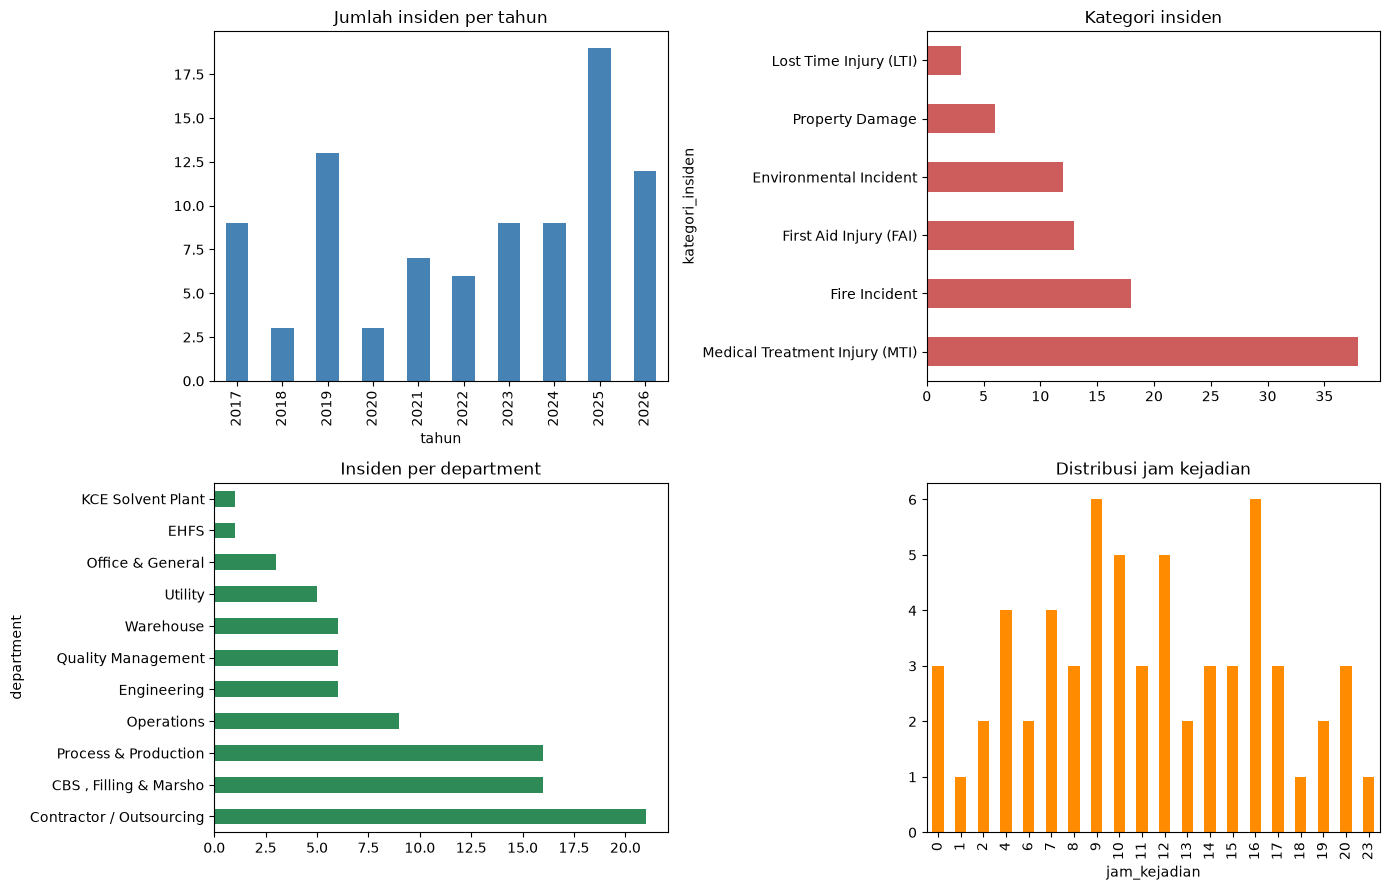

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

df["tahun"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Jumlah insiden per tahun")

df["kategori_insiden"].value_counts().plot(kind="barh", ax=axes[0, 1], color="indianred")
axes[0, 1].set_title("Kategori insiden")

df["department"].value_counts().plot(kind="barh", ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Insiden per department")

df["jam_kejadian"].dropna().astype(int).value_counts().sort_index().plot(kind="bar", ax=axes[1, 1], color="darkorange")
axes[1, 1].set_title("Distribusi jam kejadian")

plt.tight_layout()
plt.show()

## 13. Susun kolom final & ekspor

In [20]:
FINAL_COLS = [
    "nomor_insiden", "jenis_laporan", "kode_unit", "has_nomor_insiden",
    "tanggal_kejadian", "hari_kejadian", "tahun", "bulan", "periode", "is_weekend",
    "jam_mulai", "jam_selesai", "jam_kejadian", "shift", "lokasi",
    "tanggal_pelaporan", "lag_pelaporan_hari",
    "department", "nama_korban", "nik", "jabatan", "ada_korban_teridentifikasi",
    "supervisor_langsung", "dept_head", "deskripsi_kejadian",
    "tindakan_tidak_aman", "kondisi_tidak_aman", "faktor_pribadi", "faktor_pekerjaan",
    "n_tindakan_tidak_aman", "n_kondisi_tidak_aman", "n_faktor_pribadi", "n_faktor_pekerjaan",
    "tipe_kecelakaan", "kategori_insiden", "tingkat_insiden", "is_injury",
    "estimasi_biaya", "lost_worked_days",
    "tindakan_perbaikan", "n_tindakan_perbaikan",
    "status_investigasi", "status_capa", "source",
]
df_clean = df[FINAL_COLS].sort_values("tanggal_kejadian", ascending=False).reset_index(drop=True)
print(df_clean.shape)
df_clean.head()

(90, 44)


,nomor_insiden,jenis_laporan,kode_unit,has_nomor_insiden,tanggal_kejadian,hari_kejadian,tahun,bulan,periode,is_weekend,jam_mulai,jam_selesai,jam_kejadian,shift,lokasi,tanggal_pelaporan,lag_pelaporan_hari,department,nama_korban,nik,jabatan,ada_korban_teridentifikasi,supervisor_langsung,dept_head,deskripsi_kejadian,tindakan_tidak_aman,kondisi_tidak_aman,faktor_pribadi,faktor_pekerjaan,n_tindakan_tidak_aman,n_kondisi_tidak_aman,n_faktor_pribadi,n_faktor_pekerjaan,tipe_kecelakaan,kategori_insiden,tingkat_insiden,is_injury,estimasi_biaya,lost_worked_days,tindakan_perbaikan,n_tindakan_perbaikan,status_investigasi,status_capa,source
0,INC/SBY/2026/012,Incident,SBY,True,2026-10-14,Rabu,2026,10,2026-10,False,10:01,11:00,10,Shift 1 (07-15),Pertigaan Genset Dan Laboratorium,2026-10-14,0,Contractor / Outsourcing,Abdullah,TGJ-092,Sipil,True,Rudi Yulianto,Didik Wijanarko,Pekerja kontraktor PT. Teknindo Global Jaya saat langsir...,NaN,NaN,NaN,NaN,0,0,0,0,Medical Treatment Injury (MTI),Medical Treatment Injury (MTI),NaN,True,NaN,0,NaN,0,Open,Unknown,Web
1,INC/SBY/2026/011,Incident,SBY,True,2026-10-01,Kamis,2026,10,2026-10,False,07:01,08:00,7,Shift 1 (07-15),Jalan Teluk Bayur,2026-10-01,0,Operations,Thomas Theo Filus,22001501,Bulking Officer,True,Indra Hadianto,Indahwati,Pada Saat keluar dari Jalan Teluk Amurang menuju jalan T...,NaN,Terdapat kendaraan dari arah lain melaju dengan kencang ...,NaN,NaN,0,1,0,0,Medical Treatment Injury (MTI),Medical Treatment Injury (MTI),NaN,True,NaN,0,Training keselamatan berkendara,1,Closed,Open,Web
2,INC/SBY/2026/010,Incident,SBY,True,2026-09-26,Sabtu,2026,9,2026-09,True,14:01,15:00,14,Shift 1 (07-15),Saluran Bak Dct Refinery 3-4,2026-09-27,1,Contractor / Outsourcing,Ahmad Syafiq Madani,NaN,Helper,True,Rudi Yulianto,Didik Wijanarko,pekerja Kontraktor PT.Pilar Putra Perkasa melakukan peke...,Mengabaikan potensi bahaya tekanan dan suhu tinggi dari ...,Jalur steam hanya diikat/dihubungkan menggunakan selang ...,pengawas tidak memahami bahaya kegagalan material akibat...,ob Safety Analysis (JSA) dibuat tanpa mengidentifikasi b...,2,1,2,2,Medical Treatment Injury (MTI),Medical Treatment Injury (MTI),NaN,True,NaN,0,Perubahan jalur steam trap; Melakukan koordinasi dan sur...,4,Closed,Closed,Web
3,INC/SBY/2026/009,Incident,SBY,True,2026-09-16,Rabu,2026,9,2026-09,False,06:01,07:00,6,Shift 3 (23-07),Jalan Raya Margorejo,2026-09-16,0,Utility,Sayful Anwar Alamsyah,05010973,Operator,True,Sugiantoro,Didik Wijanarko,Ketika berangkat kerja menuju pabrik sekitar pukul 06.30...,terdapat kendaraan motor melaju menerobos lampu merah,NaN,NaN,NaN,1,0,0,0,Medical Treatment Injury (MTI),Medical Treatment Injury (MTI),NaN,True,NaN,0,Sosialisasi keselamatan berkendara,1,Closed,Open,Web
4,INC/SBY/2026/008,Incident,SBY,True,2026-09-04,Jumat,2026,9,2026-09,False,16:01,17:00,16,Shift 2 (15-23),Warehouse Finish Goods Marsho,2026-09-05,1,Warehouse,NaN,NaN,Unknown,False,Beny Kristian,Indahwati,Sekitar pukul 16:30 operator forklift GBJ Marsho sedang ...,Menata atau menumpuk barang di rak bertingkat tinggi tan...,Lantai tempat rak berdiri mengalami deformasi; Konstruks...,Belum adanya training mengenai metode pengisian produk p...,Belum adanya periodic inspection terkait kekuatan dan ke...,1,2,1,5,Property Damage LOW,Property Damage,LOW,False,NaN,0,Dilakukan assessment secara menyeluruh dengan team Racki...,5,Closed,Open,Web


In [21]:
df_clean.to_csv("Data_Incident_clean.csv", index=False)
with pd.ExcelWriter("Data_Incident_clean.xlsx") as writer:
    df_clean.to_excel(writer, sheet_name="data_clean", index=False)
    pd.Series(metadata, name="value").to_frame().to_excel(writer, sheet_name="metadata")
print("Tersimpan: Data_Incident_clean.csv & Data_Incident_clean.xlsx")

Tersimpan: Data_Incident_clean.csv & Data_Incident_clean.xlsx
